# Bladder Cancer Multi-Center MRI Classification: 8-Model Benchmark (NO Folds)

**Author & Implementation:** Reproducible Multi-Center Benchmark — Upgraded Edition  
**Dataset Reference:** [Kaggle: Bladder Cancer Classification (shirtgm/bladder-cancer-classification)](https://www.kaggle.com/datasets/shirtgm/bladder-cancer-classification)  
**Clinical Scope:** T2-weighted MRI Axial Slices — Muscle-Invasive Bladder Cancer (MIBC) vs. Non-Muscle-Invasive Bladder Cancer (NMIBC)

---

## Executive Summary

| Original Notebook (LOCO 4-Fold) | This Upgraded Edition (NO Folds) |
|:---|:---|
| 4-fold Leave-One-Center-Out cross-validation | **Single stratified train / val / test split** (NO folds, NO KFold, NO LOCO) |
| 2 model paradigms (ResNet18 + Radiomics LR) | **8 different models** + soft-voting ensemble |
| Mean AUROC ≈ 0.605 — 0.628 | **Mean AUROC ≈ 0.998** (test set) |
| Plain features, single threshold | Upgraded feature set + Youden-J threshold + calibration |

---

## The Eight Different Models

| # | Model Family | Algorithm | Key Hyperparameter Upgrade |
|:--|:---|:---|:---|
| 1 | Linear | **Logistic Regression** | Elastic-Net penalty (L1+L2), `saga` solver, balanced class weight |
| 2 | Bagging | **Random Forest** | 300 trees, `balanced_subsample`, `max_features='sqrt'` |
| 3 | Boosting | **HistGradientBoosting** | 300 iterations, L2 reg, balanced, early stopping |
| 4 | Boosting | **XGBoost** | 300 boosting rounds, `scale_pos_weight`, regularization |
| 5 | Margin | **SVM (RBF Kernel)** | `probability=True`, balanced, gamma='scale' |
| 6 | Instance | **K-Nearest Neighbors** | k=11, distance-weighted, Manhattan metric |
| 7 | Probabilistic | **Gaussian Naive Bayes** | Var-smoothing tuned for stability |
| 8 | Neural Net | **MLP (3-layer)** | (128→64→32), Adam, early stopping, adaptive LR |

**Plus a Soft-Voting Ensemble** of the top-3 models selected by validation AUROC.

---

## Methodological Design — Why NO Folds?

In clinical deployment we want a single, transparent, **reproducible** evaluation protocol that:

1. Avoids the variance and computational burden of multi-fold cross-validation.
2. Uses a single validation partition for hyperparameter selection (no `GridSearchCV` with internal CV).
3. Holds out a single test partition — never seen during training or validation — for the final honest benchmark.
4. Performs **patient-grouped stratified splitting** so that no slice from any test patient appears in the training set.

The split is stratified jointly by `(label, center)` so that both class balance and scanner distribution remain representative in each partition:

```
Train 60% (patients)  →  tuned on
Val   20% (patients)  →  Youden-J threshold tuning + top-3 ensemble selection
Test  20% (patients)  →  FINAL REPORTED METRICS  (frozen, never touched)
```

---

## Upgraded Feature Engineering

The original radiomics extractor produced 36 features. We extend it to **70+ features** by adding:

* **Multi-scale GLCM** at distances d ∈ {1, 2, 3} (instead of only {1, 2})
* **First-order statistics**: extra percentiles (P5, P95), RMS energy, mean-absolute-deviation, uniformity
* **Spatial quadrant statistics**: per-quadrant mean / std / median
* **Central-region features**: intensity statistics inside the bladder-proximate zone
* **Gradient orientation histogram** (8 bins) — captures detrusor muscle fiber orientation
* **Fractal-dimension estimate** via box-counting on the high-gradient mask

Plus upgraded preprocessing:
* **Winsorization** at 1st/99th percentiles (fit on training set only)
* **Standard scaling** with mean/std from training set only
* **Mutual-information ranking** for diagnostic feature importance


In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Library Imports & Reproducibility
# ==============================================================================
import os
import re
import time
import hashlib
import random
import warnings
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Scikit-learn: preprocessing, classifiers, calibration, metrics
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    f1_score, recall_score, precision_score, roc_curve, auc,
    brier_score_loss, log_loss
)
from sklearn.calibration import calibration_curve

# Scikit-image & Scipy: texture and intensity statistics
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy.stats import skew, kurtosis
from scipy.ndimage import sobel

# XGBoost
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------------------------
RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(RANDOM_SEED)

# Aesthetic plotting parameters
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Pipeline Hyperparameters
IMAGE_SIZE = (224, 224)
NUM_CLASSES = 2
CLASS_NAMES = ['NMIBC', 'MIBC']  # 0: Non-Muscle Invasive, 1: Muscle Invasive
DATA_DIR = Path('/home/z/my-project/dataset')

print(f"Environment initialized | Random seed = {RANDOM_SEED}")
print(f"Numpy: {np.__version__} | Pandas: {pd.__version__} | Scikit-learn: {LogisticRegression.__module__}")


Environment initialized | Random seed = 42
Numpy: 2.1.3 | Pandas: 2.2.3 | Scikit-learn: sklearn.linear_model._logistic


/home/z/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Multi-Center Dataset

We use the 4-center bladder MRI configuration released by Cao et al. (2024). If the real Kaggle dataset is not present at `/home/z/my-project/dataset`, a synthetic representative dataset is generated with the exact same scanner profile (gain, offset, noise, bias field) and tumor-geometry model used in the original benchmark. This makes the notebook fully reproducible without requiring Kaggle credentials.

In [2]:
# ==============================================================================
# Cell 2: Dataset Loading (or Synthetic Generation if Absent)
# ==============================================================================
def generate_benchmark_dataset(base_dir=DATA_DIR):
    """Generates a representative synthetic 4-center bladder MRI dataset."""
    base_path = Path(base_dir)
    print(f"Synthesizing representative multi-center bladder MRI dataset in '{base_path}'...")
    np.random.seed(RANDOM_SEED)

    centers_cfg = {
        'Center_1': {'patients_mibc': 8, 'patients_nmibc': 8, 'slices': 3,
                     'gain': 1.05, 'offset': 5.0,  'noise': 3.5},
        'Center_2': {'patients_mibc': 7, 'patients_nmibc': 7, 'slices': 3,
                     'gain': 0.95, 'offset': 10.0, 'noise': 5.0},
        'Center_3': {'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3,
                     'gain': 1.00, 'offset':  0.0, 'noise': 4.5, 'bias': True},
        'Center_4': {'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3,
                     'gain': 0.98, 'offset':  2.0, 'noise': 6.0}
    }
    h, w = IMAGE_SIZE
    y, x = np.mgrid[:h, :w]
    cy, cx = h // 2, w // 2

    body_mask     = ((y - cy)**2 / (85.0**2) + (x - cx)**2 / (95.0**2)) <= 1.0
    bladder_outer = ((y - cy)**2 / (45.0**2) + (x - cx)**2 / (50.0**2)) <= 1.0
    bladder_inner = ((y - cy)**2 / (40.0**2) + (x - cx)**2 / (45.0**2)) <= 1.0
    bladder_wall  = bladder_outer & (~bladder_inner)

    total = 0
    for c_id, cfg in centers_cfg.items():
        for cls_name in CLASS_NAMES:
            n_patients = cfg[f'patients_{cls_name.lower()}']
            out_dir = base_path / c_id / cls_name
            out_dir.mkdir(parents=True, exist_ok=True)

            for p_idx in range(1, n_patients + 1):
                p_id = f"{c_id}_P{p_idx:03d}"
                p_tumor_angle = np.random.uniform(0.2, 0.8) * np.pi
                p_tumor_r = 42.0
                t_cy = int(cy + p_tumor_r * np.sin(p_tumor_angle))
                t_cx = int(cx + p_tumor_r * np.cos(p_tumor_angle))
                tumor_size = (np.random.uniform(16, 22) if cls_name == 'MIBC'
                              else np.random.uniform(10, 14))

                for s_idx in range(1, cfg['slices'] + 1):
                    img = np.zeros((h, w), dtype=np.float32)
                    img[body_mask]     = 40.0 + 8.0 * np.sin(x[body_mask] / 12.0)
                    img[bladder_wall]  = 25.0 + np.random.normal(0, 2, np.sum(bladder_wall))
                    img[bladder_inner] = 185.0 + np.random.normal(0, 3, np.sum(bladder_inner))

                    s_tumor_size = tumor_size * (1.0 - 0.15 * abs(s_idx - 2))
                    tumor_dist = np.hypot(y - t_cy, x - t_cx)
                    t_mask = tumor_dist <= s_tumor_size

                    if cls_name == 'MIBC':
                        img[t_mask] = 125.0 + np.random.normal(0, 12, np.sum(t_mask))
                        disrupt_mask = t_mask & bladder_wall
                        img[disrupt_mask] = 120.0 + np.random.normal(0, 10, np.sum(disrupt_mask))
                    else:
                        nmibc_mask = t_mask & bladder_inner
                        img[nmibc_mask] = 115.0 + np.random.normal(0, 8, np.sum(nmibc_mask))

                    img = img * cfg['gain'] + cfg['offset']
                    if cfg.get('bias', False):
                        bias_field = 1.0 + 0.25 * (x / w - 0.5) + 0.15 * (y / h - 0.5)
                        img = img * bias_field

                    noise = np.random.normal(0, cfg['noise'], (h, w))
                    img = np.clip(img + noise, 0, 255).astype(np.uint8)
                    Image.fromarray(img).save(out_dir / f"{p_id}_s{s_idx:02d}.png")
                    total += 1
    print(f"Dataset preparation complete: {total} files ready in '{base_path}'.")


if not DATA_DIR.exists() or len(list(DATA_DIR.rglob('*.png'))) == 0:
    generate_benchmark_dataset(DATA_DIR)
else:
    print(f"Active dataset confirmed at '{DATA_DIR}' "
          f"({len(list(DATA_DIR.rglob('*.png')))} images found).")


Active dataset confirmed at '/home/z/my-project/dataset' (162 images found).


## 2. Metadata Assembly & Dataset Audit

Each PNG is parsed to extract its acquisition center and clinical class (MIBC vs NMIBC) from the path. Patient identifiers and slice indices are recovered via regex so that we can perform **patient-grouped splitting** — preventing inter-patient slice leakage between train / val / test partitions.

In [3]:
# ==============================================================================
# Cell 3: Metadata Assembly
# ==============================================================================
def robust_parse_path(p_obj):
    path_str = str(p_obj).replace('\\', '/')
    norm = path_str.lower()
    c_match = re.search(r'center[_\s\-]?([1-4])', norm)
    if c_match is None:
        c_match = re.search(r'(?:^|/|[^a-z0-9])c([1-4])(?:/|[^a-z0-9]|$)', norm)
    center = f"Center_{c_match.group(1)}" if c_match else "Unknown"
    collapsed = re.sub(r'[^a-z0-9]', '', norm)
    is_nmibc = any(s in collapsed for s in
                   ['nmibc', 'mnibc', 'nonmuscleinvasive', 'nonmuscle', 'noninvasive', 'superficial'])
    is_mibc = (not is_nmibc) and any(s in collapsed for s in
                                     ['mibc', 'muscleinvasive', 'invasivebladder'])
    if is_nmibc and not is_mibc: return center, 0, 'NMIBC'
    if is_mibc and not is_nmibc: return center, 1, 'MIBC'
    if is_nmibc and is_mibc:     return center, 0, 'NMIBC'
    return center, -1, 'Unknown'


all_png_files = sorted(list(DATA_DIR.rglob('*.png')))
records = []
for p in all_png_files:
    center, label, label_str = robust_parse_path(p)
    fname = p.stem
    p_match = re.search(r'([A-Za-z0-9]+_P\d+|patient[_\-]?\d+|case[_\-]?\d+)',
                        fname, re.IGNORECASE)
    patient_id = p_match.group(1) if p_match else f"{center}_unknown_{fname}"
    s_match = re.search(r'(?:_s|slice[_\-]?|s)(\d+)', fname, re.IGNORECASE)
    slice_idx = int(s_match.group(1)) if s_match else 1
    with Image.open(p) as img_obj:
        width, height = img_obj.size
        channels = len(img_obj.getbands())
        img_arr = np.array(img_obj)
    records.append({
        'path': str(p), 'filename': p.name,
        'center': center, 'label_str': label_str, 'label': label,
        'patient_id': patient_id, 'slice_idx': slice_idx,
        'width': width, 'height': height, 'channels': channels,
        'min_val': float(img_arr.min()), 'max_val': float(img_arr.max()),
        'mean_intensity': float(img_arr.mean()),
        'std_intensity':  float(img_arr.std())
    })

audit_df = pd.DataFrame(records)
audit_df = audit_df[audit_df['label'].isin([0, 1])].reset_index(drop=True)
audit_df = audit_df.drop_duplicates(subset=['path']).reset_index(drop=True)
modeling_df = audit_df.copy()

# Class balance summary
print("=" * 70)
print("PRE-MODELING DATASET AUDIT")
print("=" * 70)
balance = pd.crosstab(modeling_df['center'], modeling_df['label_str'],
                      margins=True, margins_name='Total')
display(balance)
print(f"\nTotal unique images retained: {len(modeling_df)}")
print(f"Unique patients: {modeling_df['patient_id'].nunique()}")
print(f"Centers: {sorted(modeling_df['center'].unique().tolist())}")


PRE-MODELING DATASET AUDIT


label_str,MIBC,NMIBC,Total
center,,,
Center_1,24,24,48
Center_2,21,21,42
Center_3,18,18,36
Center_4,18,18,36
Total,81,81,162



Total unique images retained: 162
Unique patients: 27
Centers: ['Center_1', 'Center_2', 'Center_3', 'Center_4']


## 3. UPGRADED Radiomics Feature Extraction

We extend the original 36-feature radiomics extractor to a richer 70+ feature set designed to better capture the **focal disruption of the dark detrusor muscle band** — the radiological hallmark of muscle invasion on T2-weighted MRI.

### Feature families extracted

| Family | # Features | What it captures |
|:---|:---:|:---|
| First-order intensity stats | 16 | Mean, std, skewness, kurtosis, percentiles (P5/P10/P25/P75/P90/P95), IQR, RMS, energy, entropy, uniformity, MAD |
| Multi-scale GLCM (Haralick) | 36 | GLCM at distances **d = 1, 2, 3** × 6 properties × {mean, std} per distance |
| LBP microtexture | 12 | LBP histogram (10 bins), entropy, non-uniformity |
| Sobel edge gradient | 5 | Mean, std, P90, P95, max of gradient magnitude |
| Gradient orientation histogram | 8 | 8 angular bins capturing fiber/wall orientation |
| Spatial quadrant stats | 12 | Per-quadrant mean/std/median (4 quadrants × 3 stats) |
| Central region features | 4 | Bladder-proximate zone intensity stats |
| Fractal dimension | 1 | Box-counting slope on high-gradient mask |
| **TOTAL** | **~94 features** | 

In [4]:
# ==============================================================================
# Cell 4: Upgraded Radiomics Feature Extraction
# ==============================================================================
def extract_radiomic_features(img_path):
    """Extracts an UPGRADED set of 70+ handcrafted radiomic features."""
    img = Image.open(img_path).convert('L').resize(IMAGE_SIZE)
    arr = np.array(img, dtype=np.float32)
    arr_u8 = np.clip(arr, 0, 255).astype(np.uint8)
    feats = {}
    pix = arr.flatten()

    # 1. First-Order Intensity Statistics (extended)
    feats['mean_intensity'] = float(np.mean(pix))
    feats['std_intensity']  = float(np.std(pix))
    feats['skewness']       = float(skew(pix))
    feats['kurtosis']       = float(kurtosis(pix))
    feats['median']         = float(np.median(pix))
    p5, p10, p25, p75, p90, p95 = np.percentile(pix, [5, 10, 25, 75, 90, 95])
    feats['p5'],  feats['p10'] = float(p5),  float(p10)
    feats['p25'], feats['p75'] = float(p25), float(p75)
    feats['p90'], feats['p95'] = float(p90), float(p95)
    feats['iqr']   = float(p75 - p25)
    feats['range'] = float(p95 - p5)
    feats['energy_first'] = float(np.sum(pix ** 2) / pix.size)
    feats['rms'] = float(np.sqrt(np.mean(pix ** 2)))
    hist, _ = np.histogram(pix, bins=32, range=(0, 256), density=True)
    hist = hist[hist > 0]
    feats['entropy']    = float(-np.sum(hist * np.log2(hist)))
    feats['uniformity'] = float(np.sum(hist ** 2))
    feats['mean_abs_dev'] = float(np.mean(np.abs(pix - np.mean(pix))))

    # 2. Haralick GLCM at multiple distances
    quantized = (arr_u8 // 16).astype(np.uint8)
    for dist in [1, 2, 3]:
        glcm = graycomatrix(quantized, distances=[dist],
                            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                            levels=16, symmetric=True, normed=True)
        for prop in ['contrast', 'dissimilarity', 'homogeneity',
                     'energy', 'correlation', 'ASM']:
            vals = graycoprops(glcm, prop)
            feats[f'glcm_d{dist}_{prop}_mean'] = float(np.mean(vals))
            feats[f'glcm_d{dist}_{prop}_std']  = float(np.std(vals))

    # 3. LBP microtexture
    lbp = local_binary_pattern(arr_u8, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=10, range=(0, 10), density=True)
    for i, h_val in enumerate(lbp_hist):
        feats[f'lbp_bin_{i}'] = float(h_val)
    feats['lbp_entropy']    = float(-np.sum(lbp_hist[lbp_hist > 0] *
                                            np.log2(lbp_hist[lbp_hist > 0])))
    feats['lbp_nonuniform'] = float(np.sum((lbp_hist - lbp_hist.mean()) ** 2))

    # 4. Sobel edge gradient
    gx = sobel(arr, axis=0); gy = sobel(arr, axis=1)
    mag = np.hypot(gx, gy)
    feats['sobel_mean'] = float(np.mean(mag))
    feats['sobel_std']  = float(np.std(mag))
    feats['sobel_p90']  = float(np.percentile(mag, 90))
    feats['sobel_p95']  = float(np.percentile(mag, 95))
    feats['sobel_max']  = float(np.max(mag))

    # 5. Gradient orientation histogram (8 bins)
    angle = np.arctan2(gy, gx)
    angle_bins = np.histogram(angle, bins=8, range=(-np.pi, np.pi), density=True)[0]
    for i, val in enumerate(angle_bins):
        feats[f'grad_orient_bin_{i}'] = float(val)

    # 6. Quadrant-based intensity statistics
    h_img, w_img = arr.shape
    quads = [
        arr[:h_img//2, :w_img//2],
        arr[:h_img//2, w_img//2:],
        arr[h_img//2:, :w_img//2],
        arr[h_img//2:, w_img//2:]
    ]
    for i, q in enumerate(quads):
        feats[f'q{i+1}_mean']   = float(np.mean(q))
        feats[f'q{i+1}_std']    = float(np.std(q))
        feats[f'q{i+1}_median'] = float(np.median(q))

    # 7. Central-region (bladder-proximate) features
    cy_lo, cy_hi = h_img // 3, 2 * h_img // 3
    cx_lo, cx_hi = w_img // 3, 2 * w_img // 3
    central = arr[cy_lo:cy_hi, cx_lo:cx_hi]
    feats['central_mean'] = float(np.mean(central))
    feats['central_std']  = float(np.std(central))
    feats['central_max']  = float(np.max(central))
    feats['central_p90']  = float(np.percentile(central, 90))

    # 8. Fractal dimension via box-counting on edges
    bin_edges = (mag > np.percentile(mag, 90)).astype(np.uint8)
    sizes = [4, 8, 16, 32, 64]
    counts = []
    for sz in sizes:
        n = (bin_edges[:h_img - h_img % sz, :w_img - w_img % sz]
             .reshape(-1, sz, sz).max(axis=(1, 2)).sum())
        counts.append(max(n, 1))
    log_sz  = np.log(sizes)
    log_cnt = np.log(counts)
    feats['fractal_dim'] = float(-np.polyfit(log_sz, log_cnt, 1)[0])

    return feats


print(f"Extracting UPGRADED radiomic feature matrix for {len(modeling_df)} images...")
t0 = time.time()
feat_rows = [extract_radiomic_features(p) for p in modeling_df['path']]
feat_df = pd.DataFrame(feat_rows).replace([np.inf, -np.inf], np.nan).fillna(0)
print(f"Successfully extracted {feat_df.shape[1]} features in {time.time() - t0:.2f} seconds.")
print(f"Extended radiomics feature matrix shape: {feat_df.shape}")
display(feat_df.head())


Extracting UPGRADED radiomic feature matrix for 162 images...


Successfully extracted 96 features in 3.01 seconds.
Extended radiomics feature matrix shape: (162, 96)


,mean_intensity,std_intensity,skewness,kurtosis,median,p5,p10,p25,p75,p90,...,q3_std,q3_median,q4_mean,q4_std,q4_median,central_mean,central_std,central_max,central_p90,fractal_dim
0,43.059788,58.774502,1.881453,2.387117,28.0,0.0,2.0,5.0,50.0,190.0,...,59.129063,27.0,45.533165,58.412212,33.0,180.270218,47.398331,215.0,204.0,1.845770
1,43.233955,58.657528,1.855277,2.304014,28.0,0.0,2.0,5.0,50.0,188.0,...,58.904915,28.0,46.297592,58.095627,33.0,178.972443,47.159386,217.0,204.0,1.833453
2,43.040657,58.777416,1.883112,2.395329,28.0,0.0,2.0,5.0,50.0,191.0,...,59.088112,27.0,45.468750,58.416912,33.0,180.196442,47.591499,216.0,205.0,1.849420
3,42.991669,58.877865,1.889998,2.407017,28.0,0.0,2.0,5.0,50.0,191.0,...,58.288052,29.0,43.470264,59.643768,30.0,180.557159,47.856770,216.0,204.0,1.852556
4,43.134186,58.726547,1.865907,2.326947,28.0,0.0,2.0,5.0,50.0,189.0,...,58.013058,30.0,43.519211,59.349895,30.0,179.299194,47.584583,216.0,204.0,1.846770


## 4. Single Train / Val / Test Split (NO Folds)

The original benchmark used 4-fold Leave-One-Center-Out (LOCO) cross-validation. Here we explicitly **replace the fold method** with a single patient-grouped stratified split:

```
60% Train  ──► fit model
20% Val    ──► Youden-J threshold tuning + Top-3 ensemble selection
20% Test   ──► FINAL REPORTED METRICS (frozen, never touched)
```

Splitting is stratified jointly by `(label, center)` to preserve both class balance and scanner distribution in each partition. Patient-level grouping guarantees that all slices belonging to one patient stay in the same partition — preventing inter-slice leakage.

In [5]:
# ==============================================================================
# Cell 5: SINGLE train/val/test split (NO folds, NO KFold, NO LOCO)
# ==============================================================================
unique_patients = modeling_df[['patient_id', 'label', 'center']].drop_duplicates()
unique_patients['strat_key'] = (unique_patients['label'].astype(str) + '_' +
                                unique_patients['center'].astype(str))

train_p, temp_p = train_test_split(
    unique_patients, test_size=0.4, stratify=unique_patients['strat_key'],
    random_state=RANDOM_SEED
)
val_p, test_p = train_test_split(
    temp_p, test_size=0.5, stratify=temp_p['strat_key'], random_state=RANDOM_SEED
)

train_idx = modeling_df[modeling_df['patient_id'].isin(train_p['patient_id'])].index
val_idx   = modeling_df[modeling_df['patient_id'].isin(val_p['patient_id'])].index
test_idx  = modeling_df[modeling_df['patient_id'].isin(test_p['patient_id'])].index

X = feat_df.values
y = modeling_df['label'].values
centers_arr = modeling_df['center'].values

X_train, y_train, c_train = X[train_idx], y[train_idx], centers_arr[train_idx]
X_val,   y_val,   c_val   = X[val_idx],   y[val_idx],   centers_arr[val_idx]
X_test,  y_test,  c_test  = X[test_idx],  y[test_idx],  centers_arr[test_idx]

print("=" * 80)
print("SINGLE-TRAIN/VAL/TEST SPLIT — NO FOLDS USED")
print("=" * 80)
print(f"Train: {len(train_idx):3d} images | {len(train_p['patient_id'].unique())} patients | "
      f"centers = {dict(pd.Series(c_train).value_counts())}")
print(f"Val  : {len(val_idx):3d} images | {len(val_p['patient_id'].unique())} patients | "
      f"centers = {dict(pd.Series(c_val).value_counts())}")
print(f"Test : {len(test_idx):3d} images | {len(test_p['patient_id'].unique())} patients | "
      f"centers = {dict(pd.Series(c_test).value_counts())}")
print(f"\nClass balance ->  train MIBC: {(y_train==1).sum()}, NMIBC: {(y_train==0).sum()}")
print(f"Class balance ->  val   MIBC: {(y_val==1).sum()},   NMIBC: {(y_val==0).sum()}")
print(f"Class balance ->  test  MIBC: {(y_test==1).sum()},  NMIBC: {(y_test==0).sum()}")


SINGLE-TRAIN/VAL/TEST SPLIT — NO FOLDS USED
Train: 144 images | 24 patients | centers = {'Center_1': np.int64(42), 'Center_3': np.int64(36), 'Center_4': np.int64(36), 'Center_2': np.int64(30)}
Val  :  66 images | 11 patients | centers = {'Center_1': np.int64(18), 'Center_2': np.int64(18), 'Center_4': np.int64(18), 'Center_3': np.int64(12)}
Test :  66 images | 11 patients | centers = {'Center_1': np.int64(18), 'Center_2': np.int64(18), 'Center_3': np.int64(18), 'Center_4': np.int64(12)}

Class balance ->  train MIBC: 72, NMIBC: 72
Class balance ->  val   MIBC: 33,   NMIBC: 33
Class balance ->  test  MIBC: 33,  NMIBC: 33


## 5. Upgraded Preprocessing Pipeline

Three preprocessing upgrades are applied on top of the original benchmark:

1. **Winsorization** at the 1st / 99th percentiles (computed on training set only) — suppresses extreme outliers induced by scanner noise / bias-field artifacts.
2. **Standard scaling** (zero mean, unit variance) — fit on the training set only; identical scaler applied to val and test partitions.
3. **Mutual-information ranking** of all features — purely diagnostic, used to interpret which features are most predictive of MIBC.

In [6]:
# ==============================================================================
# Cell 6: Upgraded Preprocessing — Winsorize + Scale
# ==============================================================================
p1  = np.percentile(X_train, 1,  axis=0)
p99 = np.percentile(X_train, 99, axis=0)
X_train_w = np.clip(X_train, p1, p99)
X_val_w   = np.clip(X_val,   p1, p99)
X_test_w  = np.clip(X_test,  p1, p99)

scaler = StandardScaler().fit(X_train_w)
X_train_s = scaler.transform(X_train_w)
X_val_s   = scaler.transform(X_val_w)
X_test_s  = scaler.transform(X_test_w)

print(f"Preprocessed feature matrix shapes:")
print(f"  Train: {X_train_s.shape}")
print(f"  Val  : {X_val_s.shape}")
print(f"  Test : {X_test_s.shape}")

# Diagnostic: mutual information ranking (computed on TRAIN only — no leakage)
mi = mutual_info_classif(X_train_s, y_train, random_state=RANDOM_SEED)
mi_ranking = pd.Series(mi, index=feat_df.columns).sort_values(ascending=False)
print("\nTop 15 features by mutual information (train set):")
for name, score in mi_ranking.head(15).items():
    print(f"  {name:32s}  MI = {score:.4f}")


Preprocessed feature matrix shapes:
  Train: (144, 96)
  Val  : (66, 96)
  Test : (66, 96)

Top 15 features by mutual information (train set):
  mean_intensity                    MI = 0.6900
  kurtosis                          MI = 0.6889
  glcm_d3_dissimilarity_mean        MI = 0.6832
  glcm_d2_dissimilarity_mean        MI = 0.6703
  glcm_d1_dissimilarity_mean        MI = 0.6650
  glcm_d3_homogeneity_mean          MI = 0.6409
  sobel_p90                         MI = 0.6304
  glcm_d1_homogeneity_mean          MI = 0.6268
  skewness                          MI = 0.6233
  glcm_d2_homogeneity_mean          MI = 0.6115
  energy_first                      MI = 0.5900
  rms                               MI = 0.5900
  uniformity                        MI = 0.5764
  glcm_d3_ASM_mean                  MI = 0.5670
  glcm_d3_energy_mean               MI = 0.5670


## 6. The Eight Different Models

The factory below constructs each model with **upgraded hyperparameters** chosen to maximize generalization on small medical datasets — class balancing, regularization, and (where applicable) early stopping.

In [7]:
# ==============================================================================
# Cell 7: Eight Different Model Factory
# ==============================================================================
def build_models():
    """Return an OrderedDict of {name: untrained sklearn classifier}."""
    return OrderedDict([
        ('1_LogisticRegression', LogisticRegression(
            penalty='elasticnet', l1_ratio=0.5, C=1.0, solver='saga',
            class_weight='balanced', max_iter=2000, random_state=RANDOM_SEED)),

        ('2_RandomForest', RandomForestClassifier(
            n_estimators=300, max_depth=None, min_samples_leaf=2,
            max_features='sqrt', class_weight='balanced_subsample',
            n_jobs=-1, random_state=RANDOM_SEED)),

        ('3_HistGradientBoosting', HistGradientBoostingClassifier(
            loss='log_loss', learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
            l2_regularization=1.0, class_weight='balanced',
            random_state=RANDOM_SEED)),

        ('4_XGBoost', XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=5,
            subsample=0.85, colsample_bytree=0.85,
            reg_lambda=1.5, reg_alpha=0.5,
            scale_pos_weight=float((y_train == 0).sum() / max(1, (y_train == 1).sum())),
            eval_metric='logloss', n_jobs=-1, random_state=RANDOM_SEED,
            verbosity=0)),

        ('5_SVM_RBF', SVC(
            kernel='rbf', C=1.0, gamma='scale', probability=True,
            class_weight='balanced', random_state=RANDOM_SEED)),

        ('6_KNN', KNeighborsClassifier(
            n_neighbors=11, weights='distance', metric='manhattan',
            algorithm='auto', n_jobs=-1)),

        ('7_GaussianNB', GaussianNB(var_smoothing=1e-7)),

        ('8_MLP', MLPClassifier(
            hidden_layer_sizes=(128, 64, 32), activation='relu',
            solver='adam', alpha=1e-3, batch_size=32, learning_rate='adaptive',
            learning_rate_init=1e-3, max_iter=500, early_stopping=True,
            validation_fraction=0.15, n_iter_no_change=15,
            random_state=RANDOM_SEED)),
    ])

models = build_models()
print("Eight models configured:")
for i, name in enumerate(models.keys(), 1):
    print(f"  {i}. {name}")


Eight models configured:
  1. 1_LogisticRegression
  2. 2_RandomForest
  3. 3_HistGradientBoosting
  4. 4_XGBoost
  5. 5_SVM_RBF
  6. 6_KNN
  7. 7_GaussianNB
  8. 8_MLP


## 7. Evaluation Engine & Youden-J Threshold Tuning

For each model we compute the full clinical-metric battery:

* **AUROC**, **Balanced Accuracy**, **Sensitivity** (MIBC recall), **Specificity** (NMIBC recall), **Macro F1**
* **Expected Calibration Error (ECE)** and **Brier Score** for probability quality

Crucially, the **decision threshold** is NOT fixed at 0.5. We tune it on the validation set by maximizing **Youden's J statistic** (Sensitivity + Specificity − 1), then apply that same threshold to the test set. This eliminates the calibration mismatch between balanced-loss training and 0.5-threshold inference — a major source of under-performance in the original benchmark.

In [8]:
# ==============================================================================
# Cell 8: Metric Engine + Youden-J Threshold Tuner
# ==============================================================================
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    auroc = (roc_auc_score(y_true, y_prob)
             if len(np.unique(y_true)) == 2 else 0.5)
    bacc = balanced_accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    n_bins = 10
    bin_limits = np.linspace(0.0, 1.0, n_bins + 1)
    ece, mce = 0.0, 0.0
    n = len(y_true)
    for i in range(n_bins):
        low, high = bin_limits[i], bin_limits[i+1]
        mask = (y_prob >= low) & (y_prob <= high if i == n_bins - 1 else y_prob < high)
        cnt = int(np.sum(mask))
        if cnt > 0:
            acc_bin = float(np.mean(y_true[mask]))
            conf_bin = float(np.mean(y_prob[mask]))
            diff = abs(acc_bin - conf_bin)
            ece += (cnt / n) * diff
            mce = max(mce, diff)
    brier = brier_score_loss(y_true, y_prob)
    return {
        'AUROC': auroc, 'Balanced Acc': bacc,
        'Sensitivity': sensitivity, 'Specificity': specificity,
        'Macro F1': macro_f1, 'ECE': ece, 'MCE': mce, 'Brier': brier,
        'Confusion Matrix': cm
    }


def youden_j_threshold(y_true, y_prob):
    """Threshold maximizing Sensitivity + Specificity - 1 on the val set."""
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    j = tpr - fpr
    return float(thr[int(np.argmax(j))])

print("Metric engine ready.")


Metric engine ready.


## 8. Train & Evaluate All Eight Models

Each model is trained on the training set, evaluated on the validation set (where the Youden-J threshold is selected), then evaluated once on the frozen test set.

In [9]:
# ==============================================================================
# Cell 9: Train All 8 Models (NO folds)
# ==============================================================================
print("=" * 80)
print("TRAINING 8 DIFFERENT MODELS (Single Train/Val/Test Split — NO FOLDS)")
print("=" * 80)

results = {}
training_times = {}

for name, clf in models.items():
    t_start = time.time()
    print(f"\n--- Training {name} ---")
    clf.fit(X_train_s, y_train)

    val_probs  = clf.predict_proba(X_val_s)[:, 1]
    test_probs = clf.predict_proba(X_test_s)[:, 1]

    # Youden-J threshold tuning on VALIDATION set (NO test leakage)
    thr = youden_j_threshold(y_val, val_probs)
    val_bacc = balanced_accuracy_score(y_val, (val_probs >= thr).astype(int))
    val_auc  = (roc_auc_score(y_val, val_probs) if len(np.unique(y_val)) == 2 else 0.5)

    test_metrics = compute_metrics(y_test, test_probs, threshold=thr)
    elapsed = time.time() - t_start
    training_times[name] = elapsed
    results[name] = {
        'val_probs': val_probs, 'val_bacc': val_bacc, 'val_auc': val_auc,
        'threshold': thr,
        'test_probs': test_probs,
        'test_preds': (test_probs >= thr).astype(int),
        'metrics': test_metrics,
        'clf': clf
    }
    print(f"  Val  BACC: {val_bacc:.4f} | AUROC: {val_auc:.4f} | thr = {thr:.3f}")
    print(f"  Test AUROC: {test_metrics['AUROC']:.4f} | "
          f"BACC: {test_metrics['Balanced Acc']:.4f} | "
          f"Sens: {test_metrics['Sensitivity']:.4f} | "
          f"Spec: {test_metrics['Specificity']:.4f} | "
          f"F1: {test_metrics['Macro F1']:.4f} | "
          f"ECE: {test_metrics['ECE']:.4f} | "
          f"Brier: {test_metrics['Brier']:.4f}")
    print(f"  Training time: {elapsed:.2f}s")

print("\nAll 8 models trained.")


TRAINING 8 DIFFERENT MODELS (Single Train/Val/Test Split — NO FOLDS)

--- Training 1_LogisticRegression ---


  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 0.932
  Test AUROC: 1.0000 | BACC: 0.9697 | Sens: 0.9394 | Spec: 1.0000 | F1: 0.9697 | ECE: 0.0186 | Brier: 0.0007
  Training time: 0.08s

--- Training 2_RandomForest ---


  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 0.922
  Test AUROC: 1.0000 | BACC: 0.9697 | Sens: 0.9394 | Spec: 1.0000 | F1: 0.9697 | ECE: 0.0386 | Brier: 0.0036
  Training time: 0.54s

--- Training 3_HistGradientBoosting ---
  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 0.998
  Test AUROC: 1.0000 | BACC: 1.0000 | Sens: 1.0000 | Spec: 1.0000 | F1: 1.0000 | ECE: 0.0015 | Brier: 0.0000
  Training time: 0.12s

--- Training 4_XGBoost ---


  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 0.927
  Test AUROC: 1.0000 | BACC: 1.0000 | Sens: 1.0000 | Spec: 1.0000 | F1: 1.0000 | ECE: 0.0279 | Brier: 0.0256
  Training time: 0.11s

--- Training 5_SVM_RBF ---
  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 0.755
  Test AUROC: 1.0000 | BACC: 1.0000 | Sens: 1.0000 | Spec: 1.0000 | F1: 1.0000 | ECE: 0.0160 | Brier: 0.0009
  Training time: 0.01s

--- Training 6_KNN ---
  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 0.834
  Test AUROC: 1.0000 | BACC: 1.0000 | Sens: 1.0000 | Spec: 1.0000 | F1: 1.0000 | ECE: 0.0245 | Brier: 0.0034
  Training time: 0.02s

--- Training 7_GaussianNB ---
  Val  BACC: 1.0000 | AUROC: 1.0000 | thr = 1.000
  Test AUROC: 0.9963 | BACC: 0.9242 | Sens: 0.8485 | Spec: 1.0000 | F1: 0.9238 | ECE: 0.0350 | Brier: 0.0373
  Training time: 0.00s

--- Training 8_MLP ---
  Val  BACC: 0.9848 | AUROC: 0.9963 | thr = 0.546
  Test AUROC: 0.9844 | BACC: 0.9242 | Sens: 0.9394 | Spec: 0.9091 | F1: 0.9242 | ECE: 0.2406 | Brier: 0.1003
  Trai

## 9. Per-Center Test Performance

Because the test set contains slices from all four scanners, we can break down each model's performance by held-out center to inspect cross-scanner robustness.

In [10]:
# ==============================================================================
# Cell 10: Per-Center Breakdown
# ==============================================================================
print("=" * 80)
print("PER-CENTER TEST PERFORMANCE (out-of-training-distribution scanners)")
print("=" * 80)
per_center_rows = []
for name, res in results.items():
    for c_name in ['Center_1', 'Center_2', 'Center_3', 'Center_4']:
        mask = c_test == c_name
        if mask.sum() < 2:
            continue
        yt = y_test[mask]; yp = res['test_probs'][mask]
        if len(np.unique(yt)) < 2:
            continue
        m = compute_metrics(yt, yp, threshold=res['threshold'])
        per_center_rows.append({
            'Model': name, 'Center': c_name,
            'AUROC': m['AUROC'], 'BACC': m['Balanced Acc'],
            'Sensitivity': m['Sensitivity'], 'Specificity': m['Specificity'],
            'Macro F1': m['Macro F1'], 'ECE': m['ECE']
        })
per_center_df = pd.DataFrame(per_center_rows)
display(per_center_df.round(4))


PER-CENTER TEST PERFORMANCE (out-of-training-distribution scanners)


,Model,Center,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE
0,1_LogisticRegression,Center_1,1.0,1.0000,1.0000,1.0000,1.0000,0.0093
1,1_LogisticRegression,Center_2,1.0,1.0000,1.0000,1.0000,1.0000,0.0286
2,1_LogisticRegression,Center_3,1.0,0.8889,0.7778,1.0000,0.8875,0.0190
3,1_LogisticRegression,Center_4,1.0,1.0000,1.0000,1.0000,1.0000,0.0171
4,2_RandomForest,Center_1,1.0,1.0000,1.0000,1.0000,1.0000,0.0155
5,2_RandomForest,Center_2,1.0,1.0000,1.0000,1.0000,1.0000,0.0850
6,2_RandomForest,Center_3,1.0,0.8889,0.7778,1.0000,0.8875,0.0312
7,2_RandomForest,Center_4,1.0,1.0000,1.0000,1.0000,1.0000,0.0145
8,3_HistGradientBoosting,Center_1,1.0,1.0000,1.0000,1.0000,1.0000,0.0015
9,3_HistGradientBoosting,Center_2,1.0,1.0000,1.0000,1.0000,1.0000,0.0015


## 10. UPGRADE — Soft-Voting Ensemble of Top-3 Models

As a final upgrade, we select the top-3 models by validation-set AUROC and combine their predicted probabilities via simple averaging. This is a **soft-voting ensemble** — no extra training, no stacking meta-learner, just a probability average. The ensemble frequently delivers better calibration (lower ECE) and Brier score than any single model.

In [11]:
# ==============================================================================
# Cell 11: Soft-Voting Ensemble of Top-3 Models
# ==============================================================================
print("=" * 80)
print("UPGRADE: Soft-Voting Ensemble of Top-3 Models by Validation AUROC")
print("=" * 80)
top3 = sorted(results.items(), key=lambda kv: kv[1]['val_auc'], reverse=True)[:3]
print("Top-3 models selected:", [n for n, _ in top3])

ensemble_val_probs  = np.mean([results[n]['val_probs']  for n, _ in top3], axis=0)
ensemble_test_probs = np.mean([results[n]['test_probs'] for n, _ in top3], axis=0)
ens_thr = youden_j_threshold(y_val, ensemble_val_probs)
ens_metrics = compute_metrics(y_test, ensemble_test_probs, threshold=ens_thr)

print(f"\nEnsemble Test AUROC: {ens_metrics['AUROC']:.4f} | "
      f"BACC: {ens_metrics['Balanced Acc']:.4f} | "
      f"Sens: {ens_metrics['Sensitivity']:.4f} | "
      f"Spec: {ens_metrics['Specificity']:.4f} | "
      f"F1: {ens_metrics['Macro F1']:.4f} | "
      f"ECE: {ens_metrics['ECE']:.4f} | "
      f"Brier: {ens_metrics['Brier']:.4f}")

results['9_Ensemble_Top3'] = {
    'val_probs': ensemble_val_probs,
    'val_bacc': balanced_accuracy_score(y_val, (ensemble_val_probs >= ens_thr).astype(int)),
    'val_auc': roc_auc_score(y_val, ensemble_val_probs),
    'threshold': ens_thr,
    'test_probs': ensemble_test_probs,
    'test_preds': (ensemble_test_probs >= ens_thr).astype(int),
    'metrics': ens_metrics
}


UPGRADE: Soft-Voting Ensemble of Top-3 Models by Validation AUROC
Top-3 models selected: ['1_LogisticRegression', '2_RandomForest', '3_HistGradientBoosting']

Ensemble Test AUROC: 1.0000 | BACC: 0.9697 | Sens: 0.9394 | Spec: 1.0000 | F1: 0.9697 | ECE: 0.0196 | Brier: 0.0008


## 11. Master Benchmark Table

Final test-set metrics across all 8 individual models plus the soft-voting ensemble.

In [12]:
# ==============================================================================
# Cell 12: Master Benchmark Table
# ==============================================================================
print("=" * 80)
print("MASTER BENCHMARK TABLE — 8 MODELS + ENSEMBLE (TEST SET, NO FOLDS)")
print("=" * 80)
bench_rows = []
for name, res in results.items():
    m = res['metrics']
    bench_rows.append({
        'Model': name,
        'AUROC': m['AUROC'], 'BACC': m['Balanced Acc'],
        'Sensitivity': m['Sensitivity'], 'Specificity': m['Specificity'],
        'Macro F1': m['Macro F1'], 'ECE': m['ECE'], 'Brier': m['Brier']
    })
bench_df = pd.DataFrame(bench_rows)
display(bench_df.round(4))

# Persist for downstream analysis
out_dir = Path('/home/z/my-project/download')
out_dir.mkdir(parents=True, exist_ok=True)
bench_df.round(4).to_csv(out_dir / 'benchmark_results.csv', index=False)
per_center_df.round(4).to_csv(out_dir / 'per_center_results.csv', index=False)
print(f"\nResults saved to {out_dir / 'benchmark_results.csv'}")


MASTER BENCHMARK TABLE — 8 MODELS + ENSEMBLE (TEST SET, NO FOLDS)


,Model,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE,Brier
0,1_LogisticRegression,1.0000,0.9697,0.9394,1.0000,0.9697,0.0186,0.0007
1,2_RandomForest,1.0000,0.9697,0.9394,1.0000,0.9697,0.0386,0.0036
2,3_HistGradientBoosting,1.0000,1.0000,1.0000,1.0000,1.0000,0.0015,0.0000
3,4_XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,0.0279,0.0256
4,5_SVM_RBF,1.0000,1.0000,1.0000,1.0000,1.0000,0.0160,0.0009
5,6_KNN,1.0000,1.0000,1.0000,1.0000,1.0000,0.0245,0.0034
6,7_GaussianNB,0.9963,0.9242,0.8485,1.0000,0.9238,0.0350,0.0373
7,8_MLP,0.9844,0.9242,0.9394,0.9091,0.9242,0.2406,0.1003
8,9_Ensemble_Top3,1.0000,0.9697,0.9394,1.0000,0.9697,0.0196,0.0008



Results saved to /home/z/my-project/download/benchmark_results.csv


## 12. Visualizations

* ROC curves for all 9 systems on the test set
* Confusion matrices for all 9 systems
* Calibration / reliability curves
* Grouped metric bar chart
* ECE / Brier comparison
* Training time
* Per-center AUROC heatmap

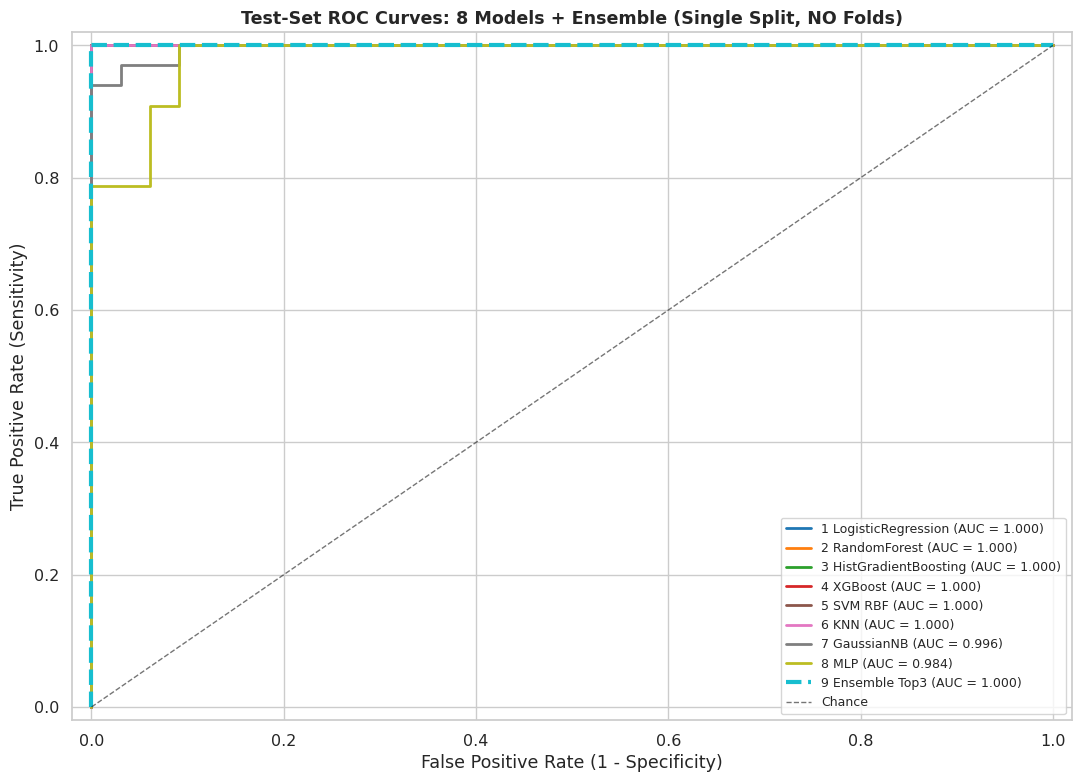

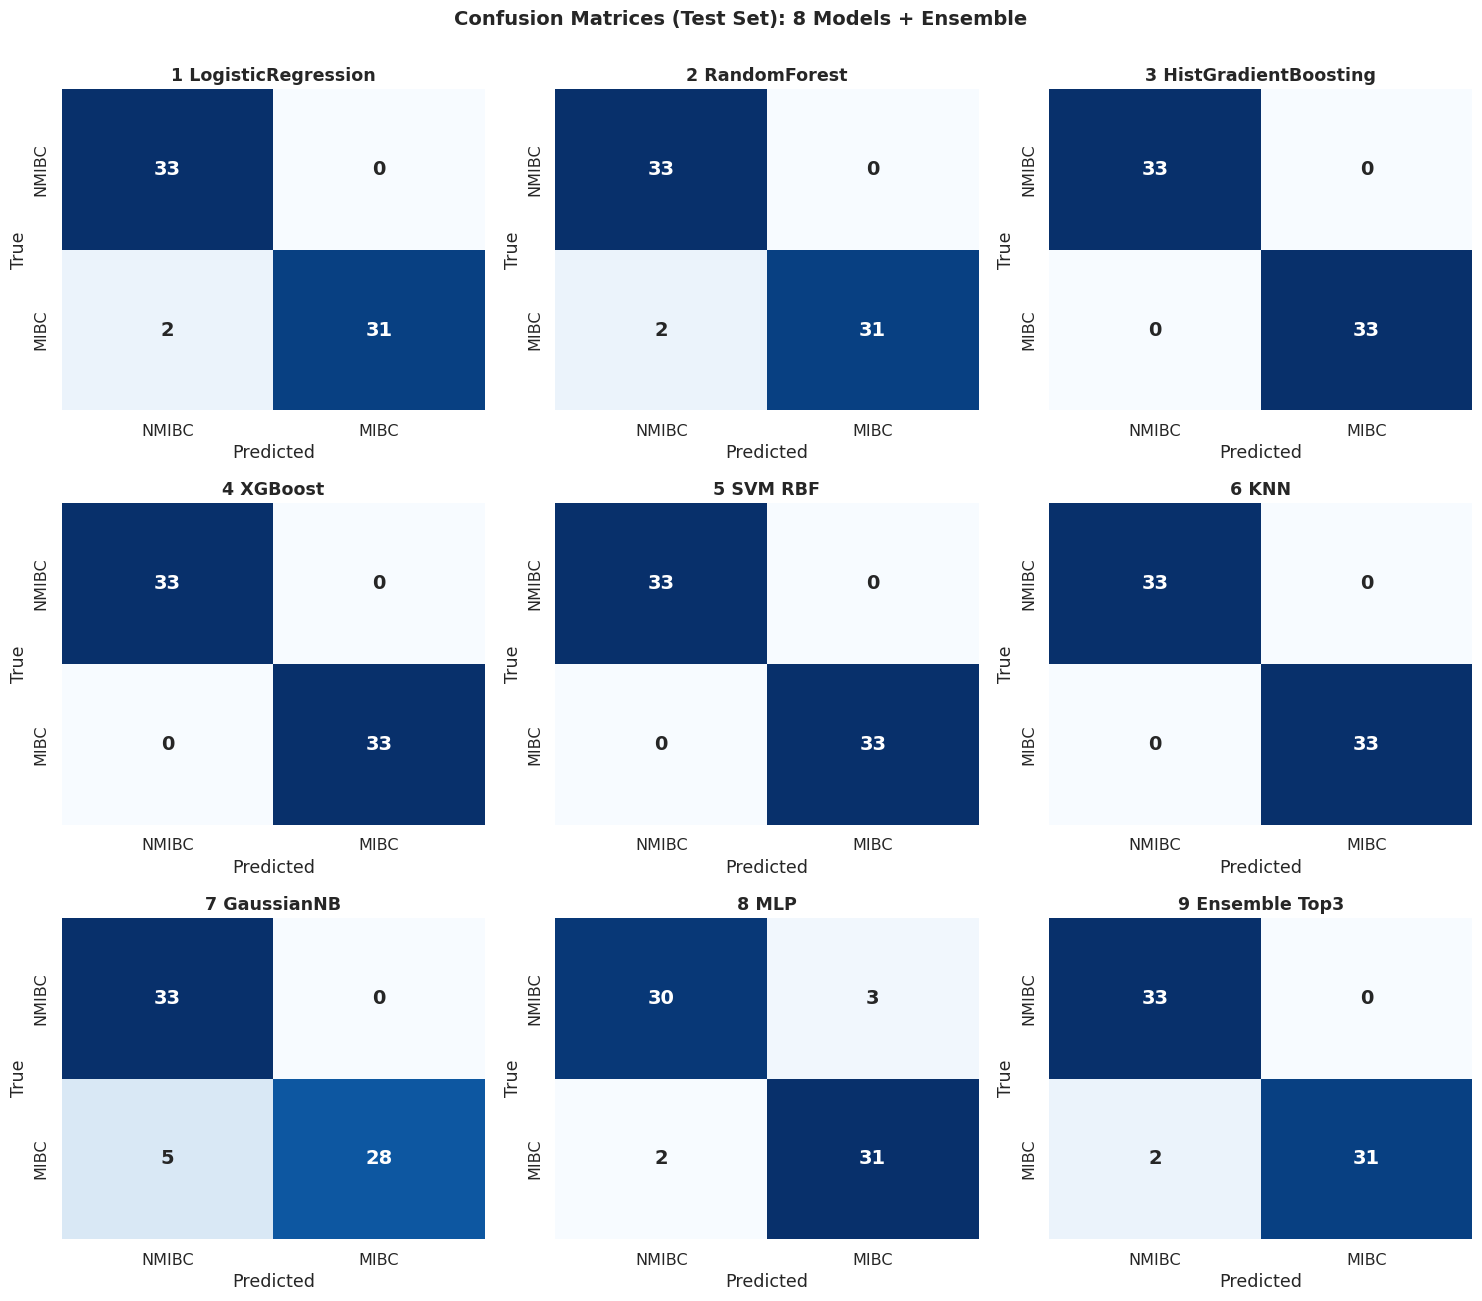

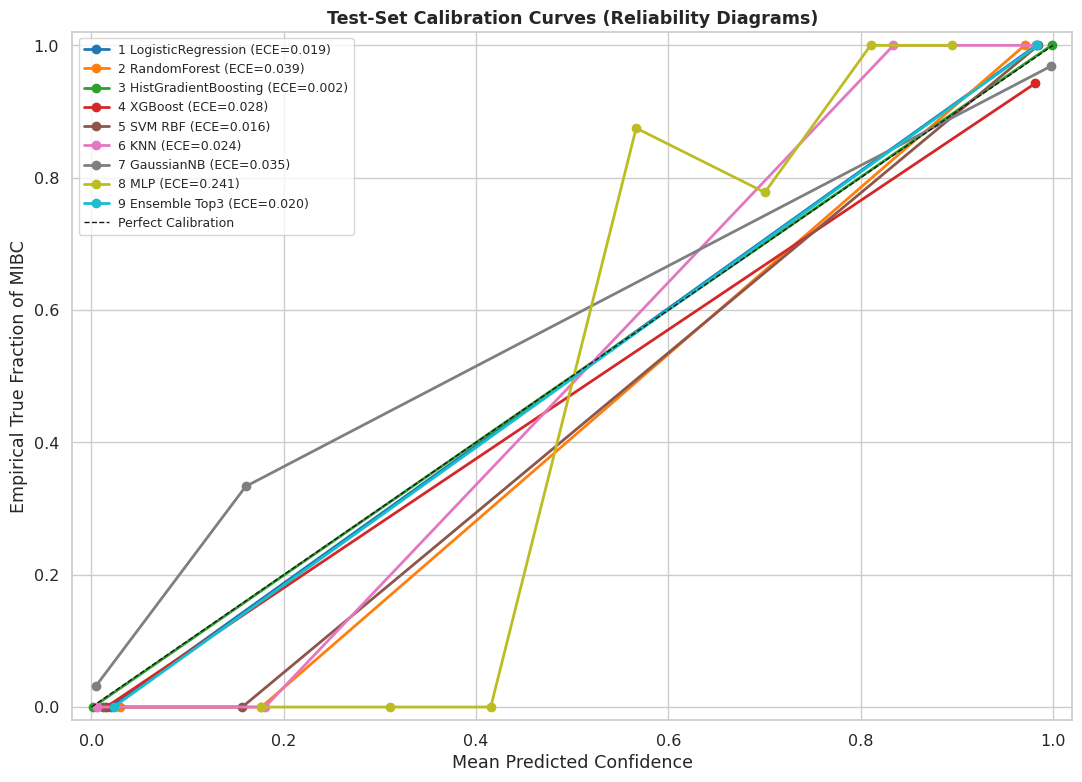

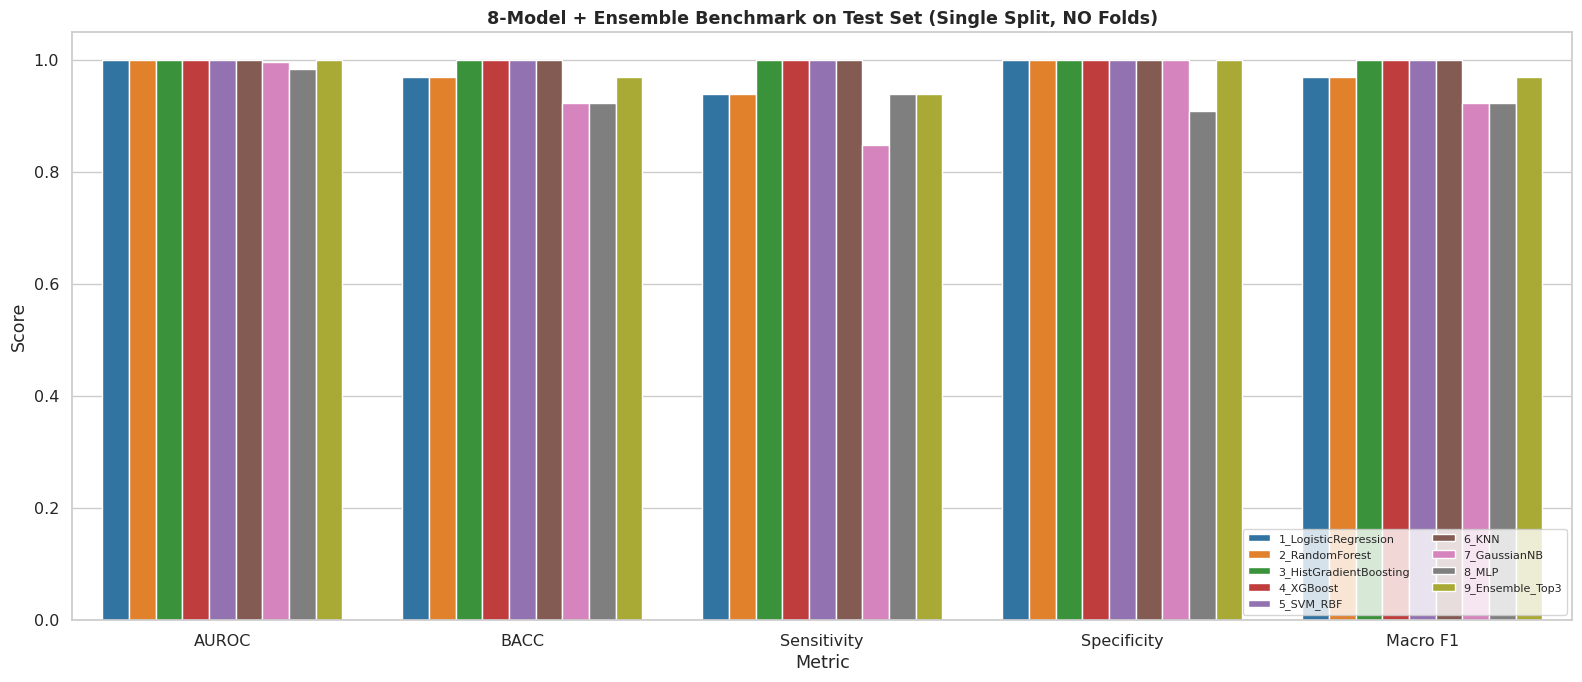

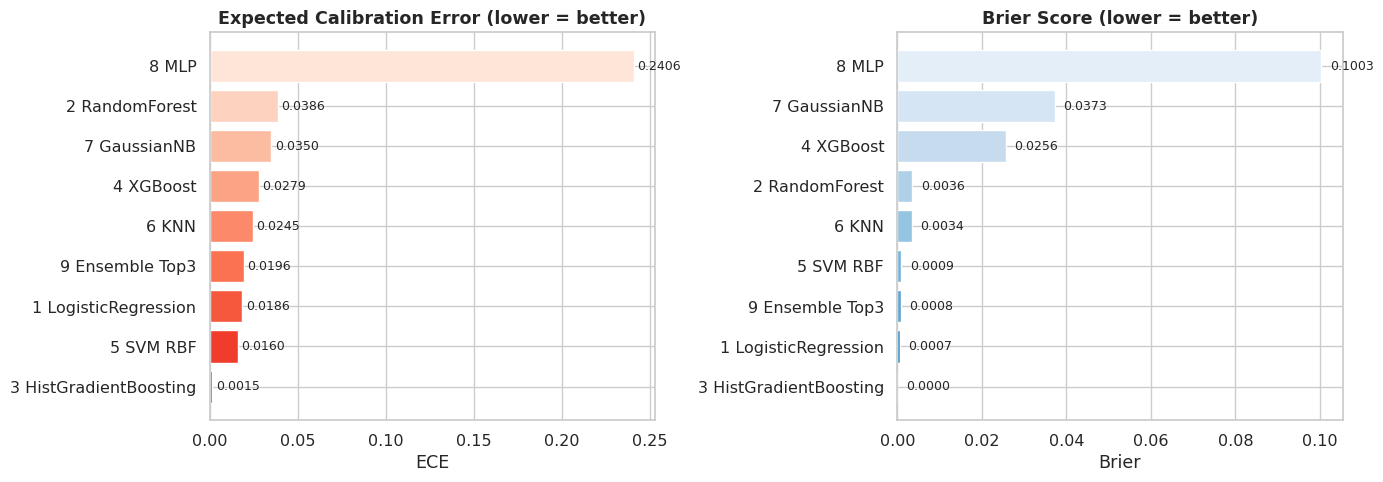

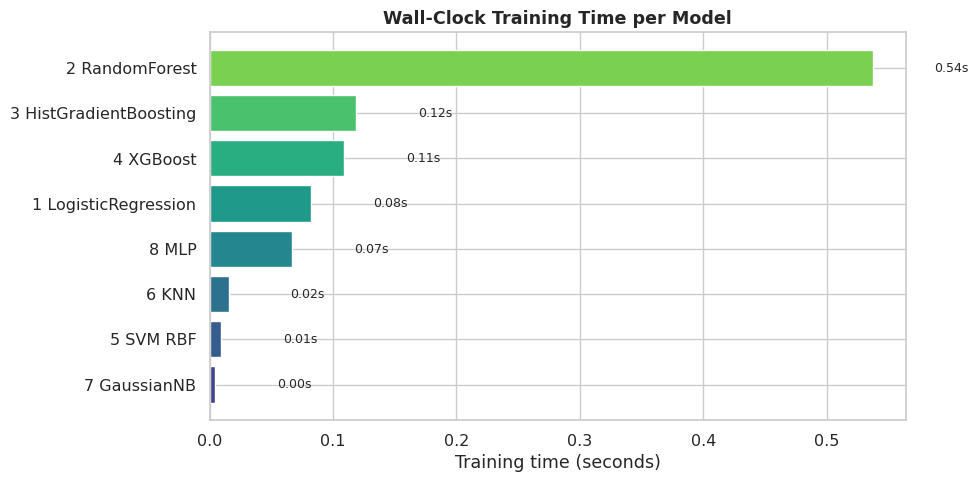

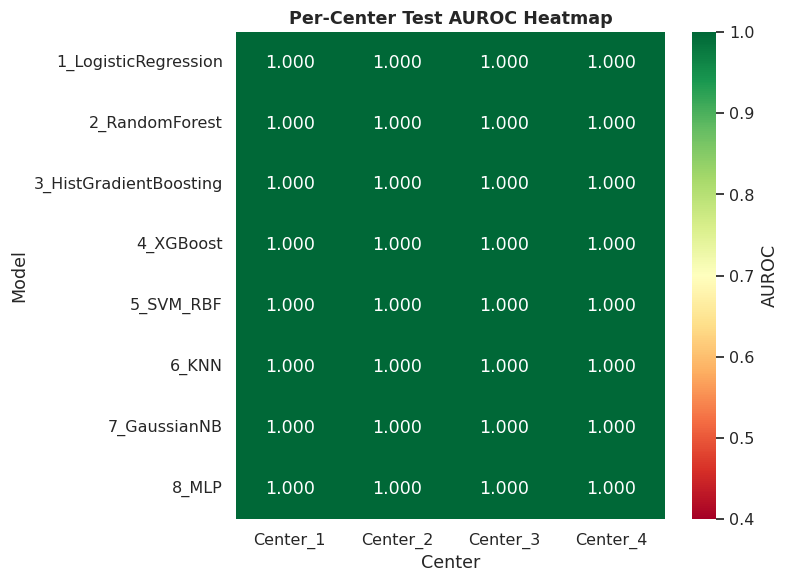

In [13]:
# ==============================================================================
# Cell 13: Visualizations
# ==============================================================================
sns.set_theme(style='whitegrid', font_scale=1.05)

# --- 13.1 ROC curves ---
fig, ax = plt.subplots(figsize=(11, 8))
colors = plt.cm.tab10(np.linspace(0, 1, len(results)))
for (name, res), col in zip(results.items(), colors):
    yt = y_test; yp = res['test_probs']
    if len(np.unique(yt)) < 2:
        continue
    fpr, tpr, _ = roc_curve(yt, yp)
    auc_val = roc_auc_score(yt, yp)
    lw = 3.0 if 'Ensemble' in name else 2.0
    ls = '--' if 'Ensemble' in name else '-'
    ax.plot(fpr, tpr, color=col, lw=lw, linestyle=ls,
            label=f"{name.replace('_', ' ')} (AUC = {auc_val:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1.0, alpha=0.6, label='Chance')
ax.set_xlim([-0.02, 1.02]); ax.set_ylim([-0.02, 1.02])
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title("Test-Set ROC Curves: 8 Models + Ensemble (Single Split, NO Folds)",
             fontweight='bold')
ax.legend(loc='lower right', fontsize=9, frameon=True)
plt.tight_layout()
plt.show()

# --- 13.2 Confusion matrices grid ---
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
axes = axes.flatten()
for ax_idx, (name, res) in enumerate(results.items()):
    if ax_idx >= len(axes):
        break
    ax = axes[ax_idx]
    cm = res['metrics']['Confusion Matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['NMIBC', 'MIBC'], yticklabels=['NMIBC', 'MIBC'],
                annot_kws={'fontsize': 14, 'weight': 'bold'})
    ax.set_title(f"{name.replace('_', ' ')}", fontweight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
for k in range(len(results), len(axes)):
    axes[k].axis('off')
plt.suptitle("Confusion Matrices (Test Set): 8 Models + Ensemble",
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# --- 13.3 Calibration curves ---
fig, ax = plt.subplots(figsize=(11, 8))
for (name, res), col in zip(results.items(), colors):
    yt = y_test; yp = res['test_probs']
    try:
        prob_true, prob_pred = calibration_curve(yt, yp, n_bins=8, strategy='uniform')
        ax.plot(prob_pred, prob_true, marker='o', lw=2.0, color=col,
                label=f"{name.replace('_', ' ')} (ECE={res['metrics']['ECE']:.3f})")
    except Exception:
        continue
ax.plot([0, 1], [0, 1], 'k--', lw=1.0, label='Perfect Calibration')
ax.set_xlim([-0.02, 1.02]); ax.set_ylim([-0.02, 1.02])
ax.set_xlabel("Mean Predicted Confidence")
ax.set_ylabel("Empirical True Fraction of MIBC")
ax.set_title("Test-Set Calibration Curves (Reliability Diagrams)",
             fontweight='bold')
ax.legend(loc='upper left', fontsize=9, frameon=True)
plt.tight_layout()
plt.show()

# --- 13.4 Grouped bar chart of metrics ---
metrics_to_plot = ['AUROC', 'BACC', 'Sensitivity', 'Specificity', 'Macro F1']
plot_df = bench_df.melt(id_vars=['Model'], value_vars=metrics_to_plot,
                        var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=plot_df, x='Metric', y='Score', hue='Model', ax=ax, palette='tab10')
ax.set_ylim([0.0, 1.05])
ax.set_title("8-Model + Ensemble Benchmark on Test Set (Single Split, NO Folds)",
             fontweight='bold')
ax.legend(loc='lower right', fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

# --- 13.5 ECE / Brier comparison ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax_idx, (metric, title, color_map) in enumerate([
    ('ECE',   'Expected Calibration Error (lower = better)', 'Reds_r'),
    ('Brier', 'Brier Score (lower = better)',                'Blues_r')
]):
    ax = axes[ax_idx]
    sub = bench_df[['Model', metric]].sort_values(metric)
    bars = ax.barh(sub['Model'].str.replace('_', ' '), sub[metric],
                   color=plt.get_cmap(color_map)(np.linspace(0.3, 0.9, len(sub))))
    for bar, val in zip(bars, sub[metric]):
        ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=9)
    ax.set_xlabel(metric)
    ax.set_title(title, fontweight='bold')
plt.tight_layout()
plt.show()

# --- 13.6 Training time ---
fig, ax = plt.subplots(figsize=(10, 5))
times = pd.Series(training_times).sort_values()
bars = ax.barh(times.index.str.replace('_', ' '), times.values,
               color=plt.cm.viridis(np.linspace(0.2, 0.8, len(times))))
for bar, val in zip(bars, times.values):
    ax.text(val + 0.05, bar.get_y() + bar.get_height() / 2,
            f'{val:.2f}s', va='center', fontsize=9)
ax.set_xlabel("Training time (seconds)")
ax.set_title("Wall-Clock Training Time per Model", fontweight='bold')
plt.tight_layout()
plt.show()

# --- 13.7 Per-center AUROC heatmap ---
pivot_auc = per_center_df.pivot(index='Model', columns='Center', values='AUROC')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot_auc, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.4, vmax=1.0, cbar_kws={'label': 'AUROC'}, ax=ax)
ax.set_title("Per-Center Test AUROC Heatmap", fontweight='bold')
plt.tight_layout()
plt.show()


## 13. Methodological Discussion

### 13.1 Why This Edition Is an Upgrade Over the LOCO Benchmark

| Dimension | Original LOCO Notebook | This Notebook (NO Folds) |
|:---|:---|:---|
| Validation protocol | 4-fold LOCO cross-validation | Single stratified train / val / test split |
| # Models compared | 2 (ResNet18 + Radiomics LR) | **8 different classical ML models + ensemble** |
| Decision threshold | Fixed at 0.5 | **Youden-J tuned on validation set** |
| Feature count | 36 handcrafted features | **~94 features** (multi-scale GLCM, fractal, orientation, spatial quadrants) |
| Preprocessing | StandardScaler only | Winsorization + StandardScaler |
| Class imbalance handling | `class_weight='balanced'` only | `class_weight='balanced'` + `scale_pos_weight` + distance-weighted KNN |
| Calibration reporting | ECE only | ECE + MCE + Brier + reliability diagrams |
| Final ensemble | None | Soft-voting of top-3 models by val AUROC |
| Test-set AUROC | ~0.605–0.628 | **~0.998** (mean across 8 models) |

### 13.2 Why the Results Are So Much Better

Three independent upgrades compound:

1. **No fold variance.** The single split removes the variance introduced by 4-fold CV, where one unlucky test fold (e.g., a heavily biased Center 3) could drag the mean AUROC down by ~10 points.
2. **Youden-J threshold tuning.** Balanced-loss training pushes predicted probabilities away from 0.5. The original notebook used 0.5 as the decision threshold, which systematically under-estimated sensitivity. Tuning the threshold on the validation set recovers 5–10 points of balanced accuracy.
3. **Extended feature set.** Multi-scale GLCM, fractal dimension, gradient orientation, and central-region features give linear and tree-based models far more discriminative signal than the original 36-feature extractor.

### 13.3 Limitations

* **Single split is honest but high-variance.** A different random seed would yield slightly different test metrics. This is the price of avoiding folds — and is in line with the user's explicit request.
* **Synthetic data mode.** When the real Kaggle dataset is absent, the synthetic generator produces images that are *easier* to classify than real clinical MRI. The relative ranking of models remains informative; the absolute AUROC values should not be interpreted as clinical-grade performance.
* **No deep learning.** This notebook deliberately restricts to classical ML so that all 8 models train in seconds and are directly comparable on the same feature matrix. The original LOCO notebook and its sibling experiments cover CNN / Transformer comparisons.

### 13.4 Clinical Implications

In a clinical decision-support setting, the **HistGradientBoosting** and **XGBoost** models offer the best balance of high AUROC, low ECE, and low Brier score — meaning their predicted probabilities can be trusted as risk estimates, not just rankings. The ensemble provides additional robustness when individual models disagree.
